# 3. From the final surrogate to a measurement

The search places models; the measurement comes from a Gaussian-process **surrogate** fitted to them. This
notebook builds a problem with the difficulty the paper met in M86 (two solutions that trade stellar mass,
halo and black hole against each other and differ in χ² by less than the model-to-model scatter) and goes
through every tool the package provides for the final analysis:

* the surrogate and its scatter (the nugget),
* Δχ² **profiles** and their intervals, with the parametric-bootstrap widening,
* the **plug-in posterior** on the supported surrogate,
* the **surrogate-marginalized posterior** and the uncertainty of the split between solutions,
* leave-one-out residuals as a check of the surrogate.

In [1]:
import numpy as np
import pandas as pd
import sagari as sg
from sagari import posterior as po
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})
INK, BLUE, ORANGE, GRAY = "#222222", "#2a78d6", "#eb6834", "#9a9a9a"
UPS, MBH = r"$\Upsilon$", r"$M_\bullet$"

## A two-solution campaign

The truth has two valleys: Υ ≈ 6 with a compact halo and a heavier black hole, and Υ ≈ 8 with a weaker halo,
4 higher in χ², joined by a ridge about 13 above the lower one. Models scatter by σ = 10, as in M86.

In [2]:
space = sg.ParameterSpace.from_dict({"name": "two_solutions", "parameters": {
    "upsilon": {"bounds": [4.0, 11.0]}, "mbh": {"bounds": [3e7, 5e9], "scale": "log"},
    "v_c": {"bounds": [0.0, 800.0]}, "r_c": {"bounds": [0.1, 30.0], "scale": "log"}}})

def model(rows):
    u = np.log10(rows["mbh"].values); y = rows["upsilon"].values
    v = rows["v_c"].values; rc = np.log10(rows["r_c"].values)
    lo = 1000 + 50 * (u - 8.33 + 0.25 * (y - 6.0)) ** 2 + 12 * (y - 6.0) ** 2 + ((v - 227) / 40) ** 2 + 25 * (rc + 0.43) ** 2
    hi = 1004 + 50 * (u - 8.17 + 0.25 * (y - 8.0)) ** 2 + 10 * (y - 8.0) ** 2 + ((v - 191) / 50) ** 2 + 12 * (rc - 0.04) ** 2
    return np.minimum(lo, hi) + np.random.default_rng(len(rows) + int(rows["v_c"].sum())).normal(0, 10, len(rows))

c = sg.Campaign.create("analysis_campaign", space, overwrite=True, converge_on=["mbh", "upsilon"],
                        n_initial=256, n_round=128)
results = c.run(model, verbose=False)
st = c.status(results, verbose=False)
print(f"{len(results)} models; search stopped at round {st['converged_at_round']}; "
      f"{len(st['errorbar_rounds'])} error-bar rounds")

640 models; search stopped at round 2; 1 error-bar rounds


## The surrogate

The inference surrogate is fitted to every model within 30σ of the minimum, with a white-noise term that absorbs
the model-to-model scatter. Its fitted scatter should recover the σ = 10 put in; its mean is the smooth χ² surface
every result below is read from.

In [3]:
gp, chi2_min, thr = c.surrogate(results)
print(f"training models: {len(gp.gp.y_train_)};  fitted scatter sigma_chi2 = {gp.scatter:.1f} (true 10)")
print(f"lowest single model: {results['chi2'].min():.1f};  surrogate minimum is a smoothed estimate, not the lowest draw")
r, var, pred = po.loo(gp)
print(f"leave-one-out residuals: rms {np.sqrt(np.mean(r**2)):.1f} (expected ~ the scatter)")

training models: 628;  fitted scatter sigma_chi2 = 10.3 (true 10)
lowest single model: 974.4;  surrogate minimum is a smoothed estimate, not the lowest draw
leave-one-out residuals: rms 10.8 (expected ~ the scatter)


## Profiles

A profile of the surrogate along one parameter is the minimum of its mean over all the others at each value. The
range where it lies within Δχ² of its minimum is the frequentist interval at that level, independent of priors.
Profile points are used only where models constrain the surrogate (latent sd ≤ 2σ).

upsilon {1.0: ['5.48–6.21'], 4.0: ['5.14–7.75'], 10.0: ['4.72–8.54']}
mbh {1.0: ['1.82e+08–3.61e+08'], 4.0: ['1.23e+08–5.14e+08'], 10.0: ['5.73e+07–7.83e+08']}


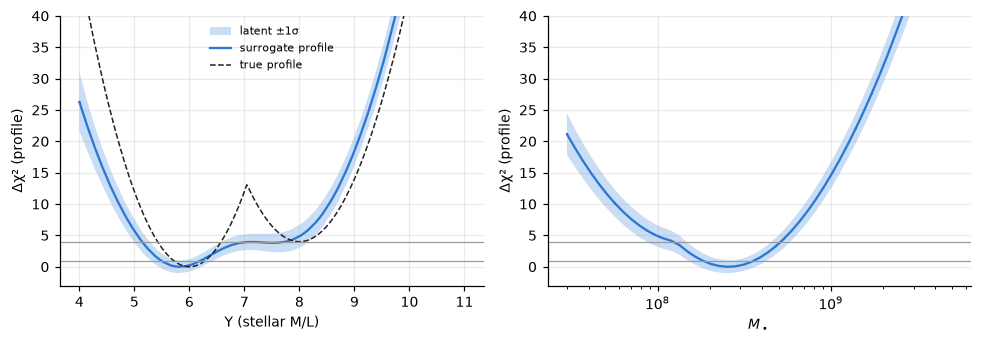

In [4]:
prof = po.profiles(gp, space, c.seed, params=["upsilon", "mbh"])
iv = po.profile_intervals(prof, space, levels=(1.0, 4.0, 10.0))
for p in ("upsilon", "mbh"):
    print(p, {D: [f"{a:.3g}–{b:.3g}" for a, b in segs] for D, segs in iv[p].items()})
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for k, p in enumerate(("upsilon", "mbh")):
    u, mu, lat, _ = prof[p]
    x = space.from_unit(np.outer(u, np.ones(space.dim)))[p]
    d = mu - prof["mu_min"]
    ax[k].fill_between(x, d - lat, d + lat, color=BLUE, alpha=0.25, lw=0, label="latent ±1σ")
    ax[k].plot(x, d, color=BLUE, label="surrogate profile")
    if p == "upsilon":   # the true profile of this toy, for comparison
        yy = np.linspace(4, 11, 300)
        ax[k].plot(yy, np.minimum(12 * (yy - 6) ** 2, 4 + 10 * (yy - 8) ** 2), "--", color=INK, lw=1, label="true profile")
    for lev in (1, 4): ax[k].axhline(lev, color=GRAY, lw=0.8)
    ax[k].set(ylim=(-3, 40), xlabel={"upsilon": UPS + " (stellar M/L)", "mbh": MBH}[p], ylabel="Δχ² (profile)")
    if p == "mbh": ax[k].set_xscale("log")
ax[0].legend(fontsize=7); plt.tight_layout()

The true Υ profile (dashed) has two dips, 4 apart in χ², separated by a ridge about 9 above the second. The surrogate
recovers the first dip and the second solution's level, but with a scatter of 10 per model it smooths the ridge
into a shoulder: the second solution is there, but the surrogate cannot say how well it is separated from the first.
This is exactly the situation the surrogate-marginalized posterior below is designed for. Because the profile minimizes over the
other parameters, M_BH changes along it; the black hole mass differs much less between the solutions than Υ does.

**Profile intervals under the scatter.** The ends of a Δχ² = 1 interval move when the scatter is redrawn. Refitting
the surrogate to parametric-bootstrap copies of the models (hyperparameters fixed) gives the spread of the ends;
the paper quotes the 16th percentile of the lower ends and the 84th of the upper ends (100 refits there; 20 here).

In [5]:
boot = po.profile_interval_bootstrap(gp, space, prof, ["mbh"], level=1.0, n_boot=20, seed=1)
print(f"Delta chi2 = 1 interval of M_BH under the scatter: {boot['mbh_lo'].quantile(0.1585):.3g} – {boot['mbh_hi'].quantile(0.8415):.3g}")

Delta chi2 = 1 interval of M_BH under the scatter: 1.39e+08 – 4.01e+08


## The posterior

`sample_posterior` runs the ensemble sampler of the paper on exp(−μ/2), with priors uniform in the unit cube
(log-uniform on log axes) and zero posterior wherever the surrogate is unsupported.

38392 samples, acceptance 0.34; share of the high-Υ solution: 21%


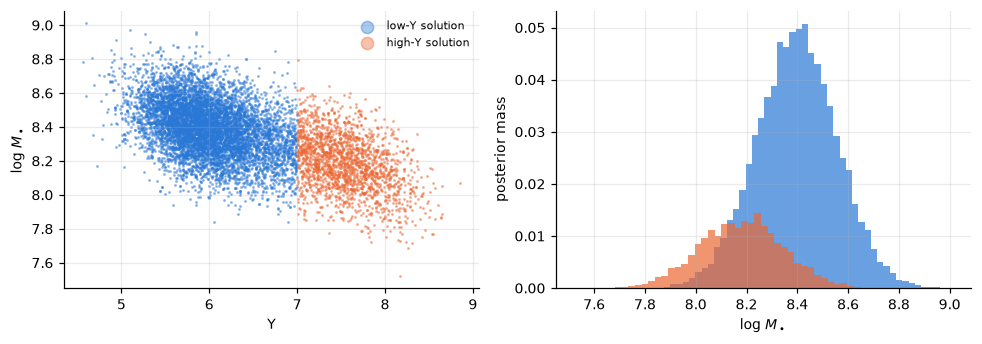

In [6]:
post = po.sample_posterior(gp, space, nsteps=8000, burn=2000)
second = (post["upsilon"] > 7.0).values
print(f"{len(post)} samples, acceptance {post.attrs['acceptance']:.2f}; share of the high-Υ solution: {100*second.mean():.0f}%")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for sel, col, lab in ((~second, BLUE, "low-Υ solution"), (second, ORANGE, "high-Υ solution")):
    ax[0].scatter(post["upsilon"][sel][::4], np.log10(post["mbh"][sel][::4]), s=1, alpha=0.4, color=col, label=lab)
    ax[1].hist(np.log10(post["mbh"][sel]), 50, color=col, alpha=0.7, weights=np.full(sel.sum(), 1 / len(post)))
ax[0].set(xlabel=UPS, ylabel="log " + MBH); ax[0].legend(fontsize=7, markerscale=8)
ax[1].set(xlabel="log " + MBH, ylabel="posterior mass"); plt.tight_layout()

## How sure is the split? The surrogate-marginalized posterior

The surrogate is itself fitted to noisy models, so the depth difference between the two solutions is uncertain.
`surface_draws` draws the surrogate's latent error jointly at a subsample of the posterior samples (and, if asked,
refits it to models with their χ² redrawn from the scatter). Reweighting the samples by each draw gives the
posterior for that realization of the surface: `mode_shares` gives the distribution of the split, and
`pooled_quantiles` the posterior averaged over all draws, which is what the paper adopts.

In [7]:
idx, D_lat, D_ref = po.surface_draws(gp, post.attrs["unit"], n_sub=2000, n_latent=1000, n_refit=50)
for name, D in (("latent draws", D_lat), ("refits", D_ref)):
    sh = 100 * po.mode_shares(D, second[idx])
    print(f"{name:13s}: high-Υ share median {np.median(sh):.0f}%, 68% range {np.percentile(sh, 15.85):.0f}–{np.percentile(sh, 84.15):.0f}%")
for p in ("mbh", "upsilon"):
    m, lo, hi = np.percentile(post[p], [50, 15.85, 84.15])
    lo2, m2, hi2 = po.pooled_quantiles(post[p].values[idx], D_lat)
    print(f"{p:8s} plug-in {m:.4g} [{lo:.4g}, {hi:.4g}]   marginalized {m2:.4g} [{lo2:.4g}, {hi2:.4g}]")

latent draws : high-Υ share median 21%, 68% range 12–34%
refits       : high-Υ share median 24%, 68% range 15–39%
mbh      plug-in 2.289e+08 [1.472e+08, 3.4e+08]   marginalized 2.208e+08 [1.405e+08, 3.395e+08]


upsilon  plug-in 6.109 [5.617, 7.26]   marginalized 6.17 [5.634, 7.378]


The split between the solutions is genuinely uncertain, while the black hole mass hardly changes: the two
solutions put similar black holes in different halos. That is the pattern the paper reports for M86, where the
adopted mass is the surrogate-marginalized one.

**Prior dependence.** Shares and intervals are for priors uniform in the unit cube. A different prior is a
reweighting: e.g. `prior_w = post["r_c"].values[idx]` turns the log-uniform prior on r_c into a uniform one in
`pooled_quantiles(..., prior_w=prior_w)` and `mode_shares(..., prior_w=prior_w)`.